# 🤖 Name That LLM: Kaun se LLM ne ye passage likha?

### 🎯 Project ka goal
Ek passage (text) diya jaata hai aur humein batana hai ki **18 alag LLMs mein se kis ne likha**.
Ye ek **18-class classification** problem hai. Random guess ka accuracy sirf **~5.5%** hota hai, isliye usse upar jo bhi score aaye wo model ki asli seekh hai.

### 📂 Dataset
- File: `passages_clean.csv` (5070 passages, 296 prompts, 18 LLMs)
- **Target:** `model` column (kis LLM ne likha)
- **Text:** `text` column (passage)
- **Group:** `prompt_id` (same prompt ke saare jawab ek hi side mein rakhne ke liye)

### 🛠️ Pipeline (step by step)
| Step | Kya hoga |
|---|---|
| 1 | Libraries import aur data load |
| 2 | Target ka graph |
| 3 | Data cleaning (missing, duplicate, leakage columns) |
| 4 | Text se features banana (length, punctuation, em-dash, curly quotes, markdown) |
| 5 | LLM-wise writing style ka EDA |
| 6 | Train-test split (prompt_id ke hisaab se) aur scaling |
| 7 | 5 models ki training |
| 8 | Error analysis: TP, TN, FP, FN, confusion matrix, Accuracy, Precision, Recall, F1 |
| 9 | Models ka comparison aur overfitting check |
| 10 | Feature importance aur final conclusion |

### 🤝 5 Models (sirf wahi jo padhe hain aur is data par fit baithte hain)
Logistic Regression, Decision Tree, Random Forest, KNN, Gaussian Naive Bayes

### ⚠️ Leakage se bachav
Provider, tokens, cost, response id jaise columns se model ka naam seedha pata chal jata hai, isliye wo hata diye jaayenge. Model sirf `text` se bane features dekhega.

### ▶️ Kaise chalana hai
Notebook aur `passages_clean.csv` ek hi folder mein rakho, phir cells upar se neeche ek-ek karke chalao.

## 1. Libraries import karo
Pehle data aur graph wali libraries, phir sklearn ke models.

In [1]:
import pandas as pd  # pandas handles table-like data
import numpy as np  # numpy handles numbers and arrays
import matplotlib.pyplot as plt  # matplotlib draws graphs
import seaborn as sns  # seaborn makes prettier graphs
import warnings  # warnings module controls warning messages
warnings.filterwarnings('ignore')  # hide unnecessary warnings

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer  # turns words into numbers
from sklearn.linear_model import LogisticRegression  # model 1: Logistic Regression
from sklearn.tree import DecisionTreeClassifier  # model 2: Decision Tree
from sklearn.ensemble import RandomForestClassifier  # model 3: Random Forest
from sklearn.neighbors import KNeighborsClassifier  # model 4: KNN
from sklearn.naive_bayes import GaussianNB  # model 5: Gaussian Naive Bayes

## 2. Data load karo
CSV padho, target column ka naam badlo aur shape, info, describe dekho.

In [3]:
df = pd.read_csv('passages_clean.csv')  # load the passages file into a table

In [4]:
df = df.rename(columns={'model': 'label'})  # rename the 'model' column to 'label' (our target)
print(df.shape)  # print number of rows and columns

(5070, 42)


In [5]:
df.head(3)  # show the first 3 rows

,id,dataset_version_added,attempt,prompt_id,label,text,n_words,word_min,word_max,target_words,...,source_prompt_id,is_refusal,is_truncated,is_empty,has_markdown,in_word_range,passes_funnel,passes_funnel_regen,funnel_fail_step,max_shared_8grams_comp
0,n001__claude-fable-5__a0,1,0,n001,claude-fable-5,"When a pan is only moderately hot, a water dro...",99,40,250,95.0,...,NaN,False,False,False,False,True,True,True,NaN,0
1,n001__claude-opus-4-6__a0,1,0,n001,claude-opus-4-6,"When a water drop lands on a merely warm pan, ...",97,40,250,83.0,...,NaN,False,False,False,False,True,True,True,NaN,0
2,n001__claude-opus-4-8__a0,1,0,n001,claude-opus-4-8,"When a water drop hits a very hot pan, its und...",56,40,250,47.0,...,NaN,False,False,False,False,True,True,True,NaN,0


In [6]:
df.columns

Index(['id', 'dataset_version_added', 'attempt', 'prompt_id', 'label', 'text',
       'n_words', 'word_min', 'word_max', 'target_words', 'prompt_sent',
       'domain', 'task_type', 'topic', 'style', 'opening_phrase', 'split',
       'provider_route', 'requested_model_id', 'served_model_id',
       'served_provider', 'generated_at_utc', 'reasoning_setting',
       'finish_reason', 'finish_reason_norm', 'input_tokens', 'output_tokens',
       'reasoning_tokens', 'cost_usd', 'call_id', 'response_id',
       'n_calls_for_cell', 'source_prompt_id', 'is_refusal', 'is_truncated',
       'is_empty', 'has_markdown', 'in_word_range', 'passes_funnel',
       'passes_funnel_regen', 'funnel_fail_step', 'max_shared_8grams_comp'],
      dtype='str')

In [7]:
df.info()  # show column types and non-null counts

<class 'pandas.DataFrame'>
RangeIndex: 5070 entries, 0 to 5069
Data columns (total 42 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      5070 non-null   str    
 1   dataset_version_added   5070 non-null   int64  
 2   attempt                 5070 non-null   int64  
 3   prompt_id               5070 non-null   str    
 4   label                   5070 non-null   str    
 5   text                    5070 non-null   str    
 6   n_words                 5070 non-null   int64  
 7   word_min                5070 non-null   int64  
 8   word_max                5070 non-null   int64  
 9   target_words            5070 non-null   float64
 10  prompt_sent             5070 non-null   str    
 11  domain                  5070 non-null   str    
 12  task_type               5070 non-null   str    
 13  topic                   5070 non-null   str    
 14  style                   4926 non-null   str    
 15

In [8]:
df.describe()  # show summary statistics of numeric columns

,dataset_version_added,attempt,n_words,word_min,word_max,target_words,input_tokens,output_tokens,reasoning_tokens,cost_usd,n_calls_for_cell,max_shared_8grams_comp
count,5070.000000,5070.000000,5070.000000,5070.0,5070.0,5070.000000,5070.000000,5070.000000,4659.000000,5070.000000,5070.000000,5070.000000
mean,1.386982,0.000197,113.763905,40.0,250.0,112.951282,76.435503,1322.642998,1256.981112,0.011930,1.000197,0.017357
std,0.944373,0.014044,56.613502,0.0,0.0,56.590619,26.242170,1597.243101,1623.966657,0.014108,0.014044,0.244277
min,1.000000,0.000000,40.000000,40.0,250.0,40.000000,33.000000,49.000000,0.000000,0.000131,1.000000,0.000000
25%,1.000000,0.000000,65.000000,40.0,250.0,64.250000,58.000000,258.000000,64.000000,0.003637,1.000000,0.000000
50%,1.000000,0.000000,100.000000,40.0,250.0,99.000000,69.000000,596.500000,575.000000,0.007800,1.000000,0.000000
75%,1.000000,0.000000,155.750000,40.0,250.0,155.000000,89.000000,1818.250000,1882.000000,0.014946,1.000000,0.000000
max,5.000000,1.000000,250.000000,40.0,250.0,250.000000,171.000000,11367.000000,11185.000000,0.123998,2.000000,7.000000


## 3. Target ka graph
Dekho har LLM ke kitne passages hain (data balanced hai ya nahi).

In [9]:
cnt = df['label'].value_counts()  # count passages for each LLM
print(cnt)  # print the counts

label
claude-opus-4-6           296
claude-opus-4-8           296
claude-opus-5             296
claude-sonnet-5           296
gemini-3.1-pro-preview    296
gemini-3.6-flash          296
gemini-3.8-flash          296
gpt-5.5                   296
gpt-5.6-luna              296
gpt-5.6-sol               296
gpt-5.6-terra             296
gpt-6-astra               296
claude-fable-5            253
gemini-3.7-flash          253
glm-5.3                   253
glm-5.3-flash             253
kimi-k3                   253
qwen3.8-max               253
Name: count, dtype: int64


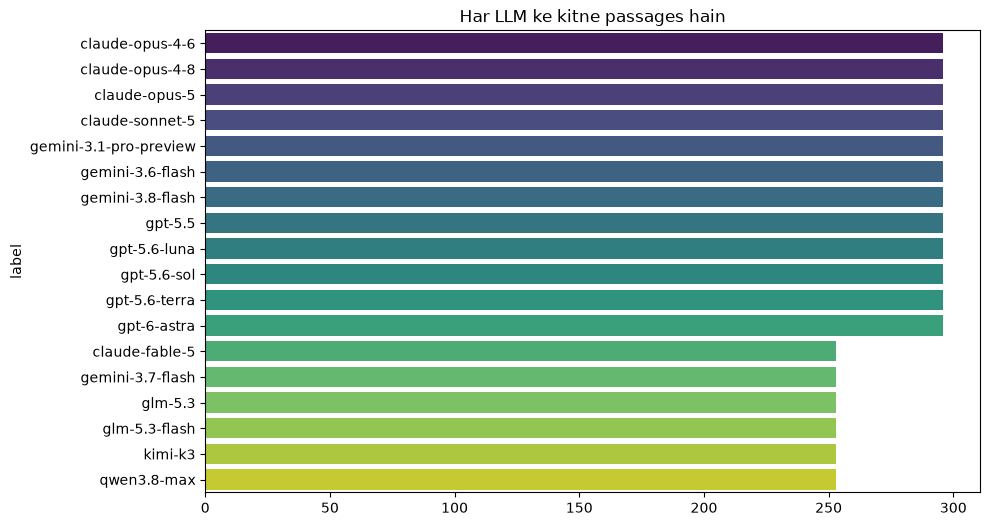

In [10]:
plt.figure(figsize=(10, 6))  # graph ka size set karo
sns.barplot(x=cnt.values, y=cnt.index, palette='viridis')  # har LLM ke passages ka bar chart banao
plt.title('Har LLM ke kitne passages hain')  # graph ka title lagao
plt.show()  # graph dikhao
# INSIGHT: 12 LLMs ke 296 aur 6 LLMs ke 253 passages hain, yaani data lagbhag balanced hai
# INSIGHT: 18 classes hain, toh random guess ka accuracy sirf ~5.5% hota hai

## 4. Data cleaning
Missing values, khali text, duplicates aur **leakage wale columns** hatao.

In [11]:
df.isnull().sum().head(10)    # check missing values in the first 10 columns

id                       0
dataset_version_added    0
attempt                  0
prompt_id                0
label                    0
text                     0
n_words                  0
word_min                 0
word_max                 0
target_words             0
dtype: int64

In [12]:
df = df.dropna(subset=['text', 'label', 'prompt_id'])  # drop rows missing text, label or prompt_id
df = df[df['text'].str.strip() != '']  # drop rows where the text is empty
print(df.shape)  # print the shape after dropping

(5070, 42)


In [13]:
print(df.duplicated(subset=['text']).sum())  # count repeated passages
df = df.drop_duplicates(subset=['text'])  # remove repeated passages

0


In [14]:
df = df.drop(columns=['id', 'dataset_version_added', 'attempt', 'n_words', 'word_min', 'word_max', 'target_words', 'prompt_sent', 'provider_route', 'requested_model_id',
'served_model_id', 'served_provider', 'generated_at_utc', 'reasoning_setting', 'finish_reason', 'finish_reason_norm', 'input_tokens', 'output_tokens', 'reasoning_tokens', 
'cost_usd', 'call_id', 'response_id', 'n_calls_for_cell', 'source_prompt_id', 'passes_funnel', 'passes_funnel_regen', 'funnel_fail_step', 'max_shared_8grams_comp'], 
errors='ignore')  # drop leakage columns (provider, tokens, cost reveal the model name)

df = df.reset_index(drop=True)  # reset the row numbers from 0
print(df.shape)  # print the cleaned shape

(5070, 14)


## 5. Text ko numbers mein badlo (feature engineering)
Har LLM ka likhne ka style alag hota hai (lambai, punctuation, markdown, em-dash, curly quotes). Wahi numbers features banenge.

In [15]:
df['len'] = df['text'].str.len()  # number of characters in the passage
df['words'] = df['text'].str.split().str.len()  # number of words in the passage
df['lines'] = df['text'].str.count('\n')  # number of new lines
df['upper'] = df['text'].str.count(r'[A-Z]')  # number of capital letters
df['digits'] = df['text'].str.count(r'\d')  # number of digits

In [16]:
df['commas'] = df['text'].str.count(',')  # number of commas
df['dots'] = df['text'].str.count(r'\.')  # number of full stops
df['qmark'] = df['text'].str.count(r'\?')  # number of question marks
df['excl'] = df['text'].str.count('!')  # number of exclamation marks
df['colon'] = df['text'].str.count(':')  # number of colons
df['semi'] = df['text'].str.count(';')  # number of semicolons

In [17]:
df['star'] = df['text'].str.count(r'\*')  # number of * (markdown bold)
df['hash'] = df['text'].str.count('#')  # number of # (markdown heading)
df['dash'] = df['text'].str.count('-')  # number of dashes (bullet points)
df['quote'] = df['text'].str.count('"')  # number of straight double quotes

In [ ]:
df['emdash'] = df['text'].str.count('—')  # number of em-dashes (Claude, GLM, Kimi use more)
df['curlyq'] = df['text'].str.count('[“”]')  # number of curly double quotes (GPT, Gemini use more)
df['curlya'] = df['text'].str.count('’')  # number of curly apostrophes (GPT, Gemini use more)

In [19]:
df['avgw'] = df['len'] / df['words']  # average word length
df['uniq'] = df['text'].str.lower().str.split().apply(set).str.len() / df['words']  # share of unique words (vocabulary richness)
df = df.replace([np.inf, -np.inf], 0).fillna(0)  # fix divide-by-zero and missing values

### Target ko number banao
LLM ke naam ko 0 se 17 tak ke number mein badlo, aur naam yaad rakho.

In [20]:
y = df['label'].astype('category').cat.codes  # LLM ke naam ko 0 se 17 tak ke number mein badlo (target)
names = df['label'].astype('category').cat.categories  # yaad rakho kaun sa number kis LLM ka hai
print(names)  # LLM ke naam print karo

Index(['claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5',
       'claude-sonnet-5', 'gemini-3.1-pro-preview', 'gemini-3.6-flash',
       'gemini-3.7-flash', 'gemini-3.8-flash', 'glm-5.3', 'glm-5.3-flash',
       'gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra',
       'gpt-6-astra', 'kimi-k3', 'qwen3.8-max'],
      dtype='str')


In [27]:
df['emdash'] = df['text'].str.count('\u2014')  # passage mein em-dash (—) kitni baar aaya
df['curlyq'] = df['text'].str.count('\u201c|\u201d')  # passage mein curly quotes (“ ”) kitni baar aaye
df['curlya'] = df['text'].str.count('\u2019')  # passage mein curly apostrophe (’) kitni baar aaya

In [28]:
print(df[['emdash', 'curlyq', 'curlya']].sum())  # teeno ka total dekho, 0 nahi aana chahiye

emdash    4183
curlyq     896
curlya    2173
dtype: int64


In [29]:
X0 = df[['len', 'words', 'lines', 'upper', 'digits', 'commas', 'dots', 'qmark', 'excl', 'colon', 'semi', 'star', 'hash', 'dash', 'quote', 'emdash', 'curlyq', 'curlya', 'avgw', 'uniq']]  # keep ONLY text-based features (no metadata, avoids leakage)
X0 = pd.get_dummies(X0)  # apply get_dummies (all features are numeric so nothing changes, safe step)
print(X0.shape)  # print the feature table shape

(5070, 20)


## 6. LLM-wise writing style (EDA)
Har LLM ke features ka average dekho. Jahan numbers alag-alag hain, wahi feature model ke kaam ka hai.

In [30]:
g = df.groupby('label')[['words', 'lines', 'emdash', 'curlyq', 'curlya', 'semi', 'star', 'hash', 'dash', 'uniq']].mean().round(2)  # average style features for each LLM
print(g)  # print the table

                         words  lines  emdash  curlyq  curlya  semi  star  \
label                                                                       
claude-fable-5          113.90   0.05    1.58    0.00    0.00  0.35  0.12   
claude-opus-4-6         115.82   0.00    1.35    0.00    0.00  0.15  0.26   
claude-opus-4-8         109.78   0.01    1.08    0.00    0.00  0.24  0.19   
claude-opus-5           115.88   0.09    1.30    0.00    0.00  0.50  0.28   
claude-sonnet-5         121.41   0.05    1.40    0.00    0.02  0.23  0.07   
gemini-3.1-pro-preview  116.23   0.10    0.22    0.03    0.46  0.19  0.09   
gemini-3.6-flash        107.58   0.07    0.31    0.01    0.46  0.23  0.06   
gemini-3.7-flash        110.29   0.06    0.40    0.03    0.57  0.30  0.08   
gemini-3.8-flash        111.19   0.11    0.35    0.03    0.61  0.32  0.11   
glm-5.3                 114.15   0.13    1.64    0.00    0.00  0.60  0.06   
glm-5.3-flash           109.76   0.00    1.62    0.00    0.00  0.53  0.07   

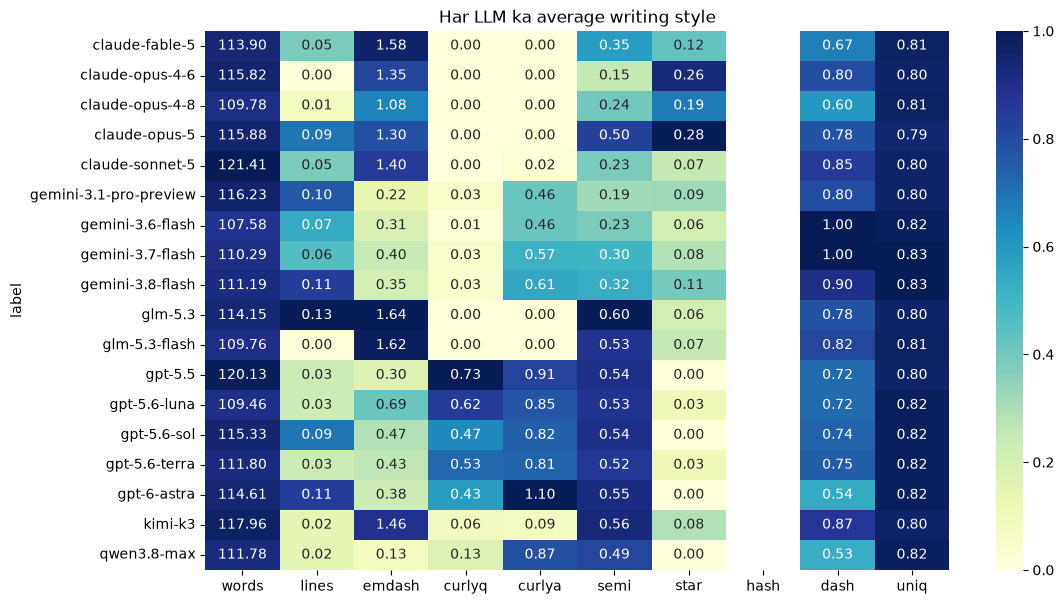

In [41]:
plt.figure(figsize=(12, 7))  # graph ka size set karo
sns.heatmap(g / g.max(), annot=g, fmt='.2f', cmap='YlGnBu')  # rang 0-1 scale par, andar asli number dikhao
plt.title('Har LLM ka average writing style')  # graph ka title lagao
plt.show()  # graph dikhao
# INSIGHT: jis column mein LLMs ke numbers alag-alag hain, wahi feature model ke kaam ka hai
# INSIGHT: jin LLMs ki row lagbhag same hai, wo aapas mein confuse honge

## 7. Train-test split (prompt_id ke hisaab se)
Same prompt ke jawab train aur test dono mein gaye toh score jhootha aayega. Isliye **prompts** ko 80/20 baantenge.

In [43]:
ids = pd.Series(df['prompt_id'].unique())  # saare alag prompt id nikalo aur Series bana lo
te_ids = ids.sample(frac=0.2, random_state=42)  # 20% prompts random chuno (random_state se har baar same aayenge)
m = df['prompt_id'].isin(te_ids)  # jis row ka prompt test wala hai wahan True, baaki False

In [44]:
X_tr = X0[~m]  # train ke features (80% prompts)
X_te = X0[m]  # test ke features (20% prompts)
y_tr = y[~m]  # train ka target
y_te = y[m]  # test ka target
print(X_tr.shape, X_te.shape)  # train aur test dono ka shape print karo

(4044, 20) (1026, 20)


### Top 200 words (TF-IDF)
Sirf train text se seekhenge, taaki test ki jaankari leak na ho.

In [ ]:
tf = TfidfVectorizer(max_features=200)

In [ ]:
tf = TfidfVectorizer(max_features=200)  # keep the 200 most important words
T_tr = tf.fit_transform(df.loc[~m, 'text'])  # learn words from train text and convert to numbers
T_te = tf.transform(df.loc[m, 'text'])  # convert test text using the same words
col = 'w_' + pd.Series(tf.get_feature_names_out())  # column names for the words, starting with w_